# Ejercicio 03 · Corpus público y clasificador de texto reproducible

**Autora:** Kimberly Pereyra · INF-8239 Ciencia de Datos II · Unidad 02

- **Pregunta:** ¿Puede un clasificador basado en TF-IDF distinguir oraciones positivas y negativas de reseñas de productos, películas y restaurantes, y qué tipo de oraciones lo confunden?
- **Corpus:** *Sentiment Labelled Sentences* — UCI ML Repository, id 331 (Kotzias, 2015). DOI 10.24432/C57604. Licencia CC BY 4.0.
- **Unidad de análisis:** una oración de una reseña. **Target:** `label` (negative / positive).
- **Métrica principal:** F1 macro (ambas clases pesan igual).

Este notebook ejecuta los mismos scripts del proyecto (`scripts/`) y muestra sus resultados. Antes de ejecutarlo: `uv run python scripts/download_data.py`.

In [1]:
import json
import runpy
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from inf8239_u02.config import ROOT, settings
from inf8239_u02.evaluation import merge_error_review

REPORTS = ROOT / "reports"
pd.set_option("display.max_colwidth", 120)

def run_script(name):
    runpy.run_path(str(ROOT / "scripts" / name), run_name="__main__")

print("Dataset:", settings.dataset_path.relative_to(ROOT), "| existe:", settings.dataset_path.exists())

Dataset: data\raw\dataset.csv | existe: True


## 1. Auditoría del corpus

{
  "sha256_csv": "c04441e6ffbae3efa900944e37cca3066bcff51a77b37b5a882db00861f827bc",
  "rows": 3000,
  "columns": [
    "text",
    "label",
    "source"
  ],
  "nulls": {
    "text": 0,
    "label": 0,
    "source": 0
  },
  "empty_texts": 0,
  "exact_duplicate_texts": 18,
  "normalized_duplicate_texts": 21,
  "deduplication": {
    "rows_before": 3000,
    "duplicate_rows_same_label": 21,
    "rows_with_conflicting_labels": 0,
    "rows_after": 2979
  },
  "class_distribution": {
    "negative": 1500,
    "positive": 1500
  },
  "class_by_source": {
    "negative": {
      "amazon": 500,
      "imdb": 500,
      "yelp": 500
    },
    "positive": {
      "amazon": 500,
      "imdb": 500,
      "yelp": 500
    }
  },
  "words_per_text": {
    "count": 3000.0,
    "mean": 11.8,
    "std": 7.9,
    "min": 1.0,
    "50%": 10.0,
    "90%": 22.0,
    "99%": 36.0,
    "max": 71.0
  }
}


Auditoría guardada en reports/audit_summary.json y reports/audit_corpus.png


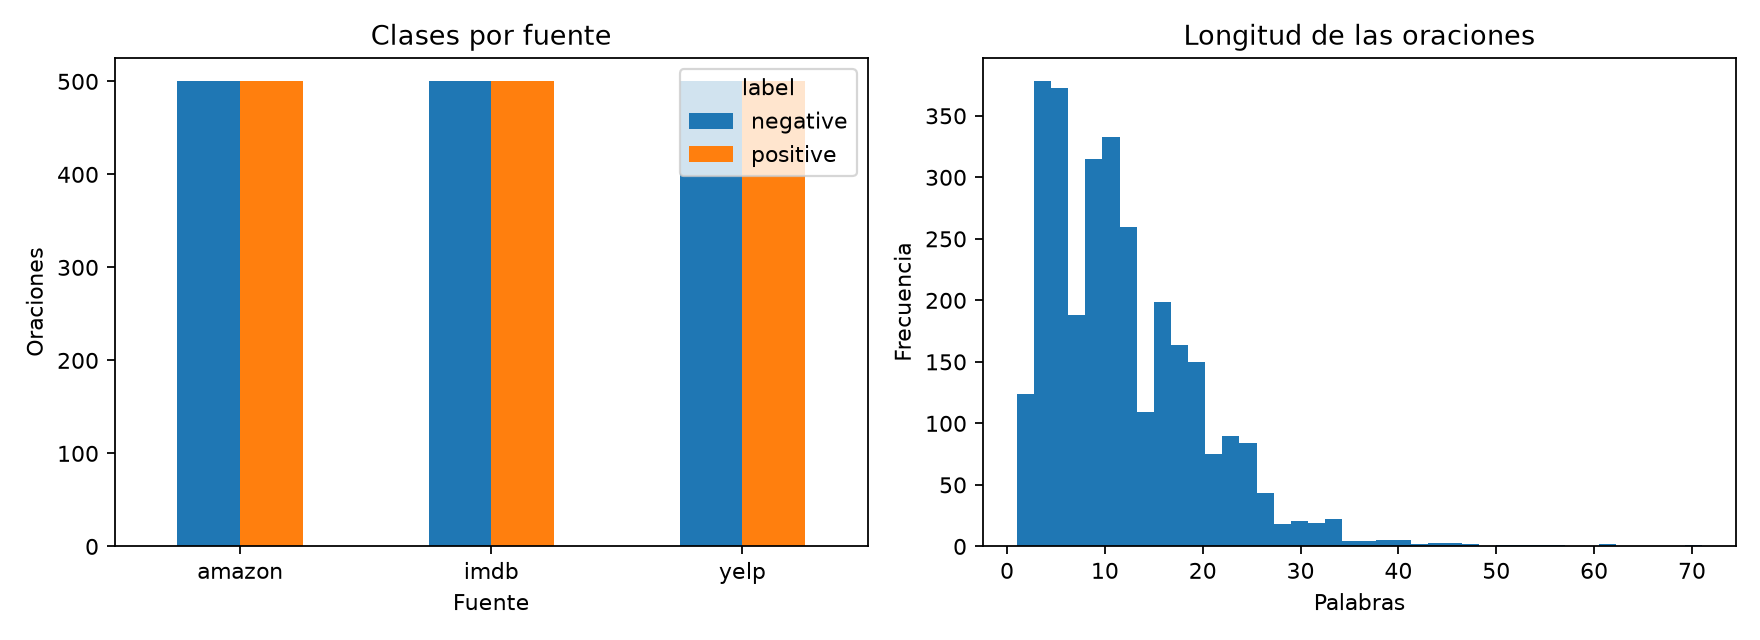

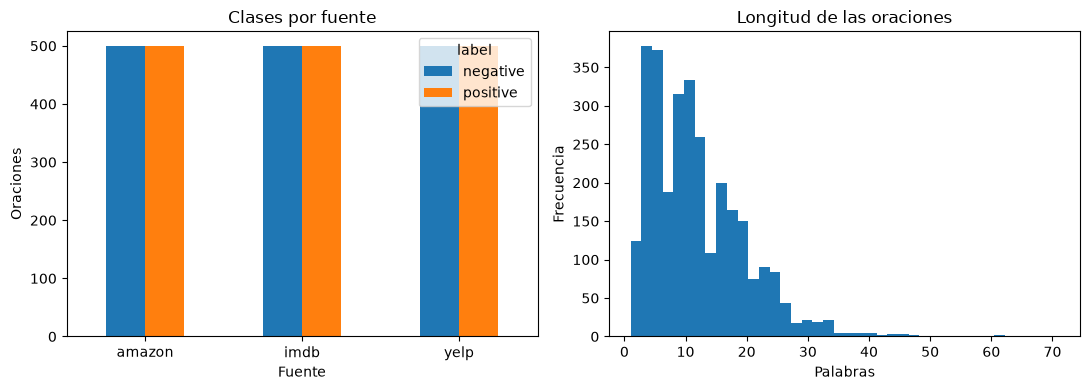

In [2]:
run_script("audit_data.py")
display(Image(REPORTS / "audit_corpus.png"))

**Observación → evidencia → interpretación → decisión**

- **Observación:** 3,000 oraciones, 1,000 por fuente, con 500 positivas y 500 negativas en cada una. No hay nulos ni textos vacíos.
- **Evidencia:** `reports/audit_summary.json` registra 18 duplicados exactos y 21 al normalizar mayúsculas y espacios, todos con la misma etiqueta (0 conflictos). La mediana es de 10 palabras y el percentil 99 de 36.
- **Interpretación:** el corpus está balanceado, así que accuracy no es engañosa, pero se reporta F1 macro. Los duplicados, aunque pocos, podrían quedar en entrenamiento y en prueba e inflar el resultado. Las oraciones son cortas, lo que deja poco contexto.
- **Decisión:** eliminar los 21 duplicados **antes** de dividir (quedan 2,979) y usar una única partición estratificada por clase y fuente, con semilla 42.

## 2. Entrenamiento: baseline y dos pipelines comparables

Deduplicación antes de dividir: {'rows_before': 3000, 'duplicate_rows_same_label': 21, 'rows_with_conflicting_labels': 0, 'rows_after': 2979}
Entrenamiento: 2234 · Prueba: 745 · Textos compartidos: 0



dummy · F1 macro=0.334
              precision    recall  f1-score   support

    negative      0.501     1.000     0.667       373
    positive      0.000     0.000     0.000       372

    accuracy                          0.501       745
   macro avg      0.250     0.500     0.334       745
weighted avg      0.251     0.501     0.334       745




naive_bayes · F1 macro=0.821
              precision    recall  f1-score   support

    negative      0.819     0.826     0.822       373
    positive      0.824     0.817     0.821       372

    accuracy                          0.821       745
   macro avg      0.821     0.821     0.821       745
weighted avg      0.821     0.821     0.821       745




logistic · F1 macro=0.811
              precision    recall  f1-score   support

    negative      0.820     0.796     0.808       373
    positive      0.802     0.825     0.813       372

    accuracy                          0.811       745
   macro avg      0.811     0.811     0.811       745
weighted avg      0.811     0.811     0.811       745




Modelo seleccionado: naive_bayes · errores en prueba: 133
Artefactos guardados en reports/ y models/


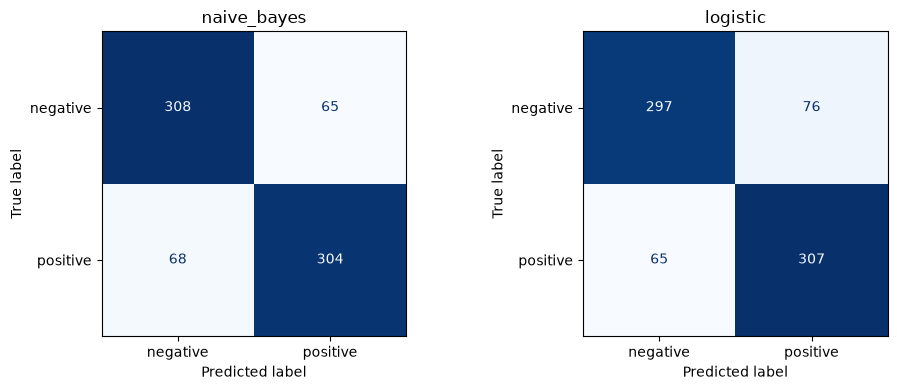

In [3]:
run_script("train_text.py")

In [4]:
metrics = pd.read_csv(REPORTS / "text_metrics.csv")
cols = ["model", "f1_macro", "accuracy", "recall_negative", "recall_positive", "fit_seconds", "predict_ms", "vocabulary"]
display(metrics[cols].round(4))
by_source = pd.read_csv(REPORTS / "text_metrics_by_source.csv")
display(by_source.pivot(index="model", columns="source", values="f1_macro").round(3))
print(json.loads((REPORTS / "selected_model.json").read_text()))

,model,f1_macro,accuracy,recall_negative,recall_positive,fit_seconds,predict_ms,vocabulary
0,naive_bayes,0.8215,0.8215,0.8257,0.8172,0.1507,33.9142,19944
1,logistic,0.8107,0.8107,0.7962,0.8253,0.2620,32.0602,19944
2,dummy,0.3336,0.5007,1.0000,0.0000,0.1476,35.3711,19944


source,amazon,imdb,yelp
model,,,
dummy,0.334,0.334,0.332
logistic,0.814,0.807,0.811
naive_bayes,0.794,0.835,0.835


{'selected': 'naive_bayes', 'train_rows': 2234, 'test_rows': 745, 'deduplication': {'rows_before': 3000, 'duplicate_rows_same_label': 21, 'rows_with_conflicting_labels': 0, 'rows_after': 2979}, 'errors_total': 133}


- **Prevención de fuga:** los tres modelos usan el mismo `Pipeline(TfidfVectorizer → modelo)`, así que el vocabulario y los pesos IDF se aprenden solo con el 75 % de entrenamiento (2,234 oraciones). El script verifica que no haya textos compartidos con la prueba (745 oraciones).
- **Baseline:** `DummyClassifier` (siempre la clase más frecuente) obtiene F1 macro 0.334 y recall 0 en la clase positiva.
- **Comparación:** Complement Naive Bayes obtiene F1 macro 0.822 y la Regresión logística 0.811. La diferencia (1.1 puntos) es pequeña con 745 oraciones de prueba, pero ambos superan ampliamente el baseline.
- **Decisión:** se selecciona **Naive Bayes** por tener el mejor F1 macro, ser el modelo más simple y rápido, y entregar probabilidades para revisar la confianza de los errores.
- **Por fuente:** con Naive Bayes, **Amazon** es la fuente más difícil (F1 0.794), frente a 0.835 en IMDb y en Yelp. El desempeño cambia según el dominio.

## 3. Matriz de confusión

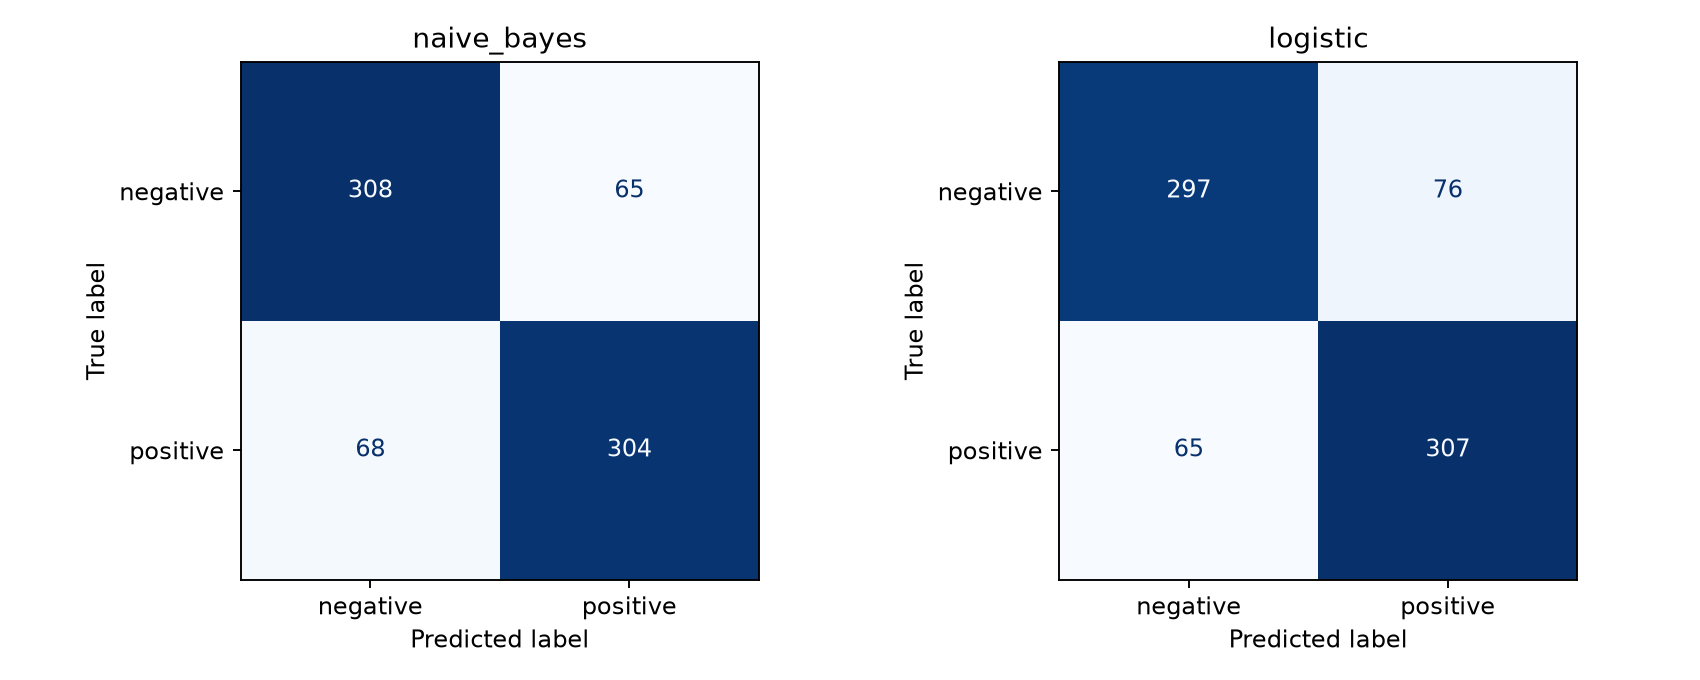

In [5]:
display(Image(REPORTS / "confusion_text.png"))

- La diagonal concentra los aciertos. Con Naive Bayes, el recall de la clase negativa (0.826) y el de la positiva (0.817) son parecidos: el modelo no favorece claramente una clase. La regresión logística, en cambio, pierde más negativas (recall 0.796).
- **Costo de la confusión:** en un uso real (por ejemplo, detectar clientes insatisfechos), una oración negativa clasificada como positiva es el error más costoso, porque esa queja no se atendería.

## 4. Análisis de 20 errores

,text,source,real,predicted,confidence,category
0,Kieslowski never ceases to amaze me.,imdb,positive,negative,0.573,negación
1,"Garbo, who showed right off the bat that her talents could carry over from the silent era (I wanted to see some of h...",imdb,positive,negative,0.673,tema fuera del dominio
2,I bought this phone as a replacement for my StarTac and have regretted it since.,amazon,negative,positive,0.524,léxico engañoso o poco frecuente
3,The Burrittos Blah!,yelp,negative,positive,0.504,texto corto o implícito
4,The result is a film that just don't look right.,imdb,negative,positive,0.524,negación
5,We also ordered the spinach and avocado salad; the ingredients were sad and the dressing literally had zero taste.,yelp,negative,positive,0.501,léxico engañoso o poco frecuente
6,It definitely was not as good as my S11.,amazon,positive,negative,0.684,etiqueta discutible
7,The warm beer didn't help.,yelp,negative,positive,0.574,negación
8,"It's so stupid to have to keep buying new chargers, car chargers, cradles, headphones and car kits every time a new ...",amazon,negative,positive,0.526,vocabulario neutro del dominio
9,This fixes all the problems.,amazon,positive,negative,0.525,léxico engañoso o poco frecuente


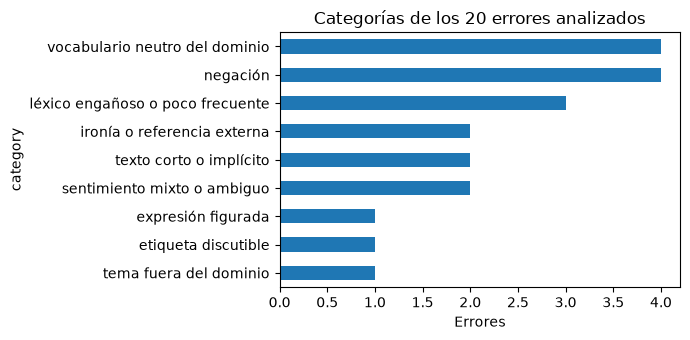

category
negación                            4
vocabulario neutro del dominio      4
léxico engañoso o poco frecuente    3
sentimiento mixto o ambiguo         2
texto corto o implícito             2
ironía o referencia externa         2
tema fuera del dominio              1
etiqueta discutible                 1
expresión figurada                  1
Name: count, dtype: int64

In [6]:
sample = pd.read_csv(REPORTS / "error_analysis_20.csv")
review = pd.read_csv(ROOT / "docs" / "error_review.csv")
reviewed = merge_error_review(sample, review)
assert (reviewed["category"] != "SIN REVISAR").all(), "Hay errores sin categoría: revise docs/error_review.csv"
reviewed.to_csv(REPORTS / "error_analysis_20_reviewed.csv", index=False)
display(reviewed[["text", "source", "real", "predicted", "confidence", "category"]])

counts = reviewed["category"].value_counts()
ax = counts.sort_values().plot.barh(figsize=(7, 3.5), title="Categorías de los 20 errores analizados")
ax.set_xlabel("Errores")
plt.tight_layout(); plt.savefig(REPORTS / "error_categories.png", dpi=160); plt.show()
counts

- **Observación:** de 133 errores de Naive Bayes en prueba, se analizaron 20 elegidos al azar (semilla 42). Casi todos tienen una confianza entre 0.50 y 0.68: el modelo duda en esos casos.
- **Evidencia:** las categorías más frecuentes son *negación* (*never ceases to amaze*, *didn't help*, *with no problem*) y *vocabulario neutro del dominio* (oraciones dominadas por palabras como *movie*, *chargers* o *cheeseburger*), seguidas de *léxico engañoso o poco frecuente* (*problems* en una oración positiva, *regretted*). También aparecen ironía, sentimiento mixto y una **etiqueta discutible** (*not as good as my S11* está marcada como positiva).
- **Interpretación:** TF-IDF trata cada palabra o par de palabras por separado, así que no entiende negaciones, sarcasmo ni el significado que una palabra toma por su contexto.
- **Hipótesis para el siguiente experimento:** marcar el alcance de la negación (por ejemplo, unir *not_good*) o usar embeddings o modelos contextuales, y comparar en estos mismos 20 casos.

## 5. Verificaciones mínimas

In [7]:
import joblib
model = joblib.load(ROOT / "models" / "text_model.joblib")
examples = ["The food was great and the staff very friendly.", "The battery died after two days, terrible."]
pred = model.predict(examples)
print(dict(zip(examples, pred)))
assert set(pred) <= {"negative", "positive"}
assert "tfidf" in model.named_steps and "model" in model.named_steps
print("Verificaciones superadas")

{'The food was great and the staff very friendly.': np.str_('positive'), 'The battery died after two days, terrible.': np.str_('negative')}
Verificaciones superadas


## Cierre interpretativo

- **Resultado principal:** Naive Bayes con TF-IDF alcanza F1 macro 0.822 frente a 0.334 del baseline; la regresión logística logra 0.811.
- **Modelo seleccionado y evidencia:** Complement Naive Bayes (mejor F1, más simple y con probabilidades); ver `reports/text_metrics.csv`.
- **Clase con mayor dificultad:** la positiva tiene un recall algo menor (0.817 frente a 0.826), pero la mayor dificultad está en la **fuente** (Amazon) y en el **tipo de oración**.
- **Tipo de error más frecuente:** negación y vocabulario neutro del dominio.
- **Impacto en el contexto:** una queja escrita con negación o ironía podría pasar como positiva y quedar sin atención.
- **Limitación del dataset:** inglés, tres sitios web, oraciones seleccionadas por tener un sentimiento claro (sin neutrales) y al menos una etiqueta discutible. No se puede aplicar a mensajes en español dominicano.
- **Decisión antes del despliegue:** usarlo solo como apoyo con revisión humana, mostrar la confianza y evaluar primero con datos del dominio real.